1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


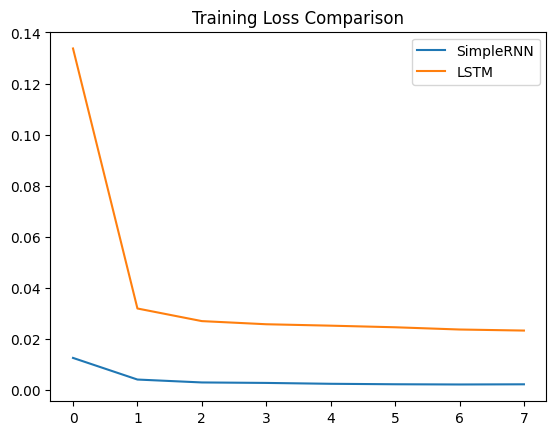

,Model,MAE,RMSE,Training Time
0,SimpleRNN,4.379234,5.299892,8.095184
1,LSTM,7.753433,8.850968,4.224801


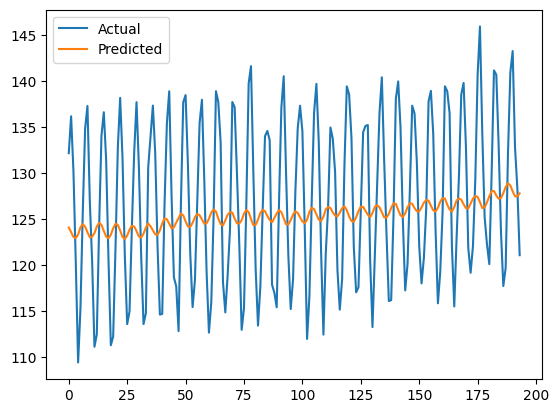

In [5]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import time

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

t = np.arange(1000)

series = (100 + 0.03*t
          + 12*np.sin(2*np.pi*t/7)
          + np.random.normal(0, 2, len(t)))

scaler = MinMaxScaler()
z = scaler.fit_transform(series[:, None]).ravel()

window = 30

X = np.array([
    z[i:i+window] for i in range(len(z)-window)
])[:, :, None]

y = z[window:]

cut = int(0.8*len(X))
Xtr, Xte = X[:cut], X[cut:]
ytr, yte = y[:cut], y[cut:]

results = []

for name, layer in [
    ("SimpleRNN", tf.keras.layers.SimpleRNN(32)),
    ("LSTM", tf.keras.layers.LSTM(32))
]:

    model = tf.keras.Sequential([
        tf.keras.layers.Input((window, 1)),
        layer,
        tf.keras.layers.Dense(1)
    ])

    model.compile("adam", "mse")

    start = time.time()

    history = model.fit(
        Xtr, ytr, epochs=8,
        validation_split=0.1, verbose=0
    )

    duration = time.time()-start

    pred = model.predict(Xte).ravel()

    actual = scaler.inverse_transform(
        yte[:, None]).ravel()

    predicted = scaler.inverse_transform(
        pred[:, None]).ravel()

    results.append([
        name,
        mean_absolute_error(actual, predicted),
        np.sqrt(mean_squared_error(actual, predicted)),
        duration
    ])

    plt.plot(history.history["loss"], label=name)

plt.legend()
plt.title("Training Loss Comparison")
plt.show()

display(pd.DataFrame(results, columns=[
    "Model", "MAE", "RMSE", "Training Time"
]))

plt.plot(actual, label="Actual")
plt.plot(predicted, label="Predicted")
plt.legend()
plt.show()
